Sally Linkenauger and Shawn June

# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [105]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [106]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [107]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


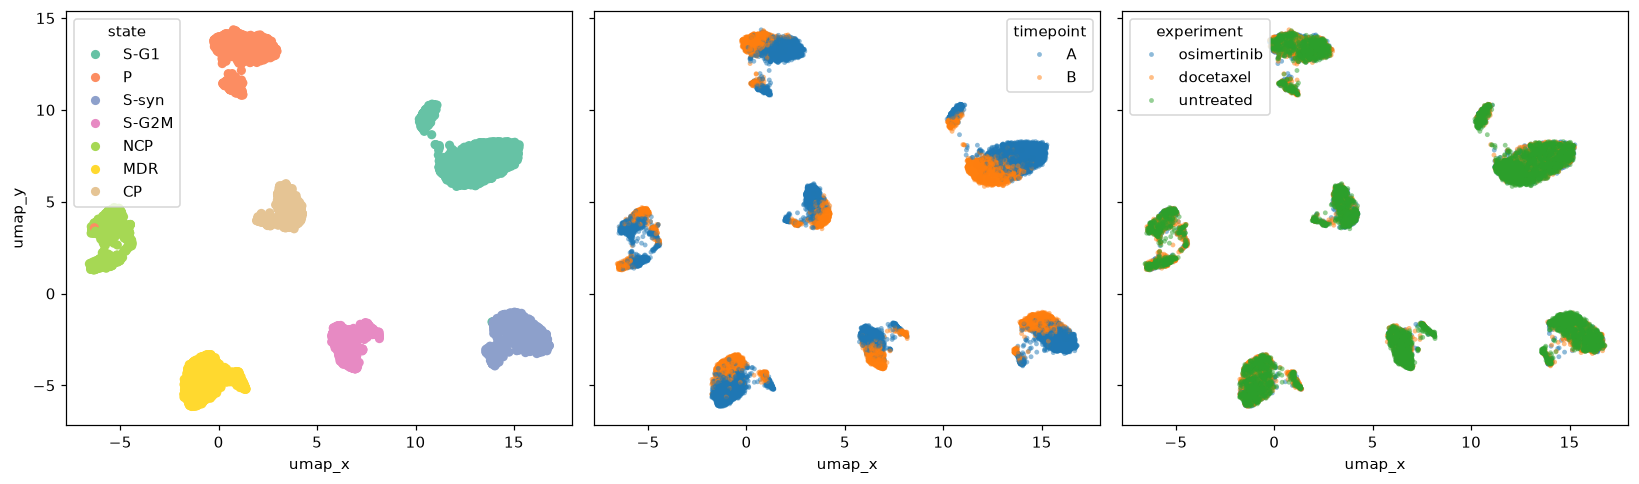

In [108]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [109]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [110]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [111]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [112]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [113]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [114]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

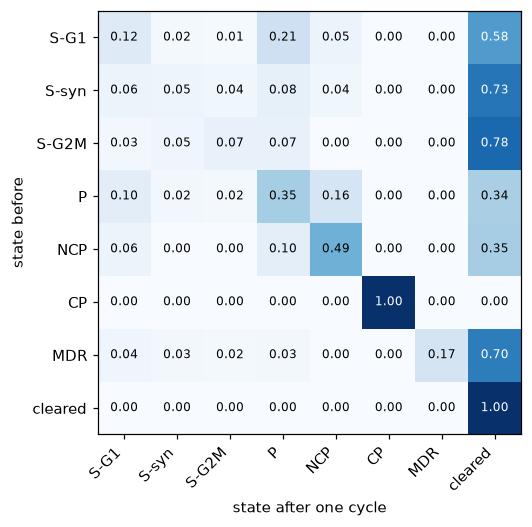

In [115]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

ANSWER:

All 279 cells that began in CP stayed in CP after one observed osimertinib cycle. The estimated CP row therefore has a 1 on its diagonal. Under repeated use of this matrix, a tumor containing even one CP cell cannot clear completely with osimertinib alone. This prediction assumes the estimated transition probabilities stay the same each cycle.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

ANSWER:

S-G2M and S-syn respond quickly: about 78% and 73%, respectively, clear in one cycle. P and NCP can remain in place or switch between one another, so we expect slower clearance. All six non-CP living states have a chance to clear each round and no route into CP. Their clearance probabilities should therefore approach 1 over time. Any cells starting in CP should persist.

In [116]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [117]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [118]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

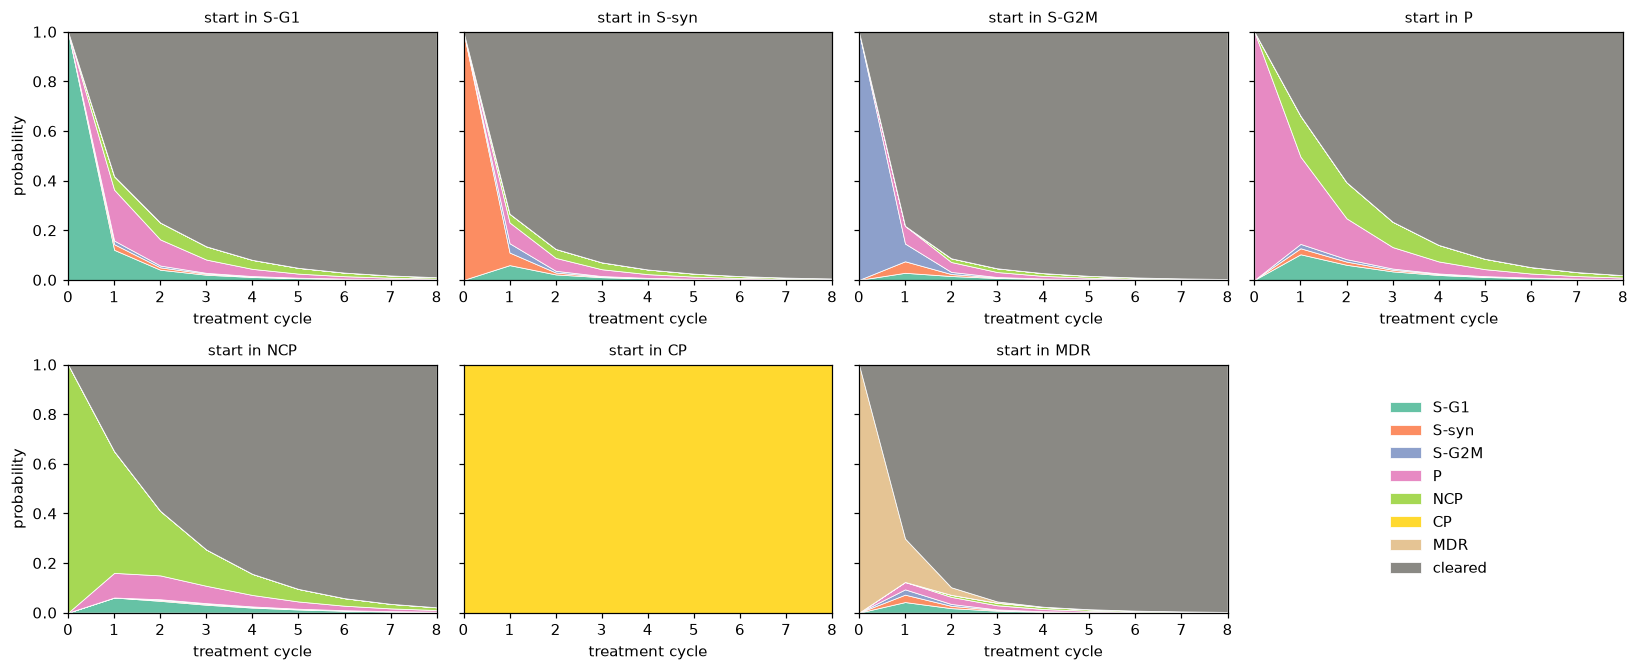

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [119]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?

ANSWER:

By cycle 8, each of the six non-CP starting states still has a small surviving fraction. With continued osimertinib their clearance probabilities approach 1. CP survives every round in this model.

- Of the states that can be cleared, which tumor lasts the longest?

ANSWER:

NCP has the greatest remaining fraction at cycles 3 and 8 (25.43% and 2.16%). About 49% of NCP cells stay in NCP each cycle and about 10% move to P. P can move back into NCP. Those paths help explain why some cells survive several rounds.

- Which starting state sticks around for the most cycles of drug?

ANSWER:

CP, because it stays in CP with probability 1.

- Which starting state results in the highest proportion of alive cells after three cycles?

ANSWER:

CP at 100%. Among the six clearable starts, NCP is highest.


In [120]:
pd.Series({s: evolve(basis(s, P_hat), P_hat, 3)[-1, :-1].sum()
           for s in STATES}, name="Fraction alive after three cycles")

S-G1     0.135156
S-syn    0.070709
S-G2M    0.046717
P        0.234360
NCP      0.254336
CP       1.000000
MDR      0.045077
Name: Fraction alive after three cycles, dtype: float64

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

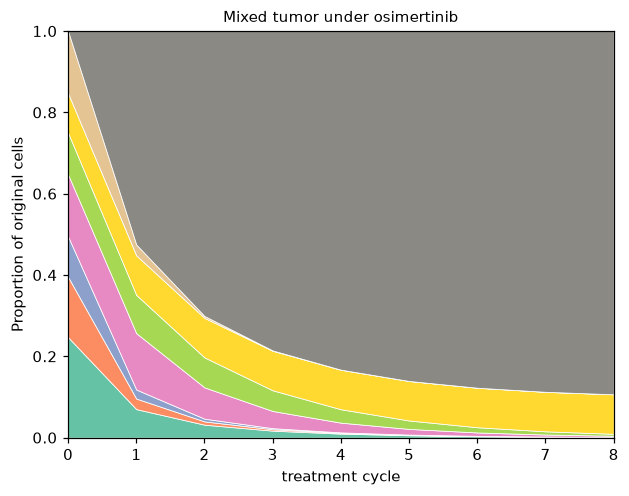

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.2470,0.1483,0.0994,0.1526,0.1024,0.0972,0.1530,0.0000
1,0.0701,0.0260,0.0222,0.1386,0.0941,0.0972,0.0268,0.5251
2,0.0319,0.0081,0.0066,0.0770,0.0737,0.0972,0.0047,0.7008
3,0.0172,0.0034,0.0027,0.0422,0.0509,0.0972,0.0008,0.7856
4,0.0099,0.0017,0.0013,0.0239,0.0330,0.0972,0.0001,0.8328
5,0.0058,0.0010,0.0007,0.0140,0.0207,0.0972,0.0000,0.8606
6,0.0035,0.0006,0.0004,0.0083,0.0128,0.0972,0.0000,0.8772
7,0.0021,0.0003,0.0002,0.0050,0.0079,0.0972,0.0000,0.8873
8,0.0013,0.0002,0.0001,0.0030,0.0048,0.0972,0.0000,0.8934


In [121]:
# Your code here

pi_mix = (
    cells.loc[cells["timepoint"] == "A", "state"]
    .value_counts(normalize=True)
    .reindex(OUTCOMES, fill_value=0)
    .to_numpy()
)

traj_mix = evolve(pi_mix, P_hat, 8)

fig, ax = plt.subplots()
plot_trajectory(traj_mix, ax, "Mixed tumor under osimertinib")
ax.set_ylabel("Proportion of original cells")
plt.show()

pd.DataFrame(traj_mix, columns=OUTCOMES).round(4)

# evolve pi_mix and plot the results

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?

ANSWER:

After eight cycles, 89.34% of the original mixed tumor has cleared and 10.66% remains alive. CP still accounts for 9.72% of the original cells, or about 91% of survivors. Its share among survivors rises because other cells clear. No other state enters CP under osimertinib. In the long run the model predicts about 9.72% CP and 90.28% cleared. P and NCP are slow to disappear but neither is absorbing.</div>

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [122]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position


doce = cells[cells["experiment"] == "docetaxel"]
drugh = cells[cells["experiment"] == "untreated"]

doce_at_A = doce[doce.timepoint == "A"][["lineage_tag", "state"]]
doce_at_B = doce[doce.timepoint == "B"][["lineage_tag", "state"]]

drugh_at_A = drugh[drugh.timepoint == "A"][["lineage_tag", "state"]]
drugh_at_B = drugh[drugh.timepoint == "B"][["lineage_tag", "state"]]


pairs_doce = pd.merge(doce_at_A, doce_at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs_doce["state_B"] = pairs_doce["state_B"].fillna("cleared")

pairs_untreated = pd.merge(drugh_at_A, drugh_at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs_untreated["state_B"] = pairs_untreated["state_B"].fillna("cleared")

STATES = [s for s in STATE_ORDER if s in set(cells["state"])]  
OUTCOMES = STATES + ["cleared"]

counts_doce = (pd.crosstab(pairs_doce.state_A, pairs_doce.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_doc = counts_doce.div(counts_doce.sum(axis=1), axis=0)

counts_untreated = (pd.crosstab(pairs_untreated.state_A, pairs_untreated.state_B)
                     .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_untreated = counts_untreated.div(counts_untreated .sum(axis=1), axis=0)

#add a cleared row that stays cleared with p = 1
P_doc.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_doc.columns})
P_untreated.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_untreated.columns})


P_osi = P_hat.to_numpy()

P_doc_df = P_doc                    
P_holiday_df = P_untreated

P_doc = P_doc_df.to_numpy()         
P_holiday = P_holiday_df.to_numpy()

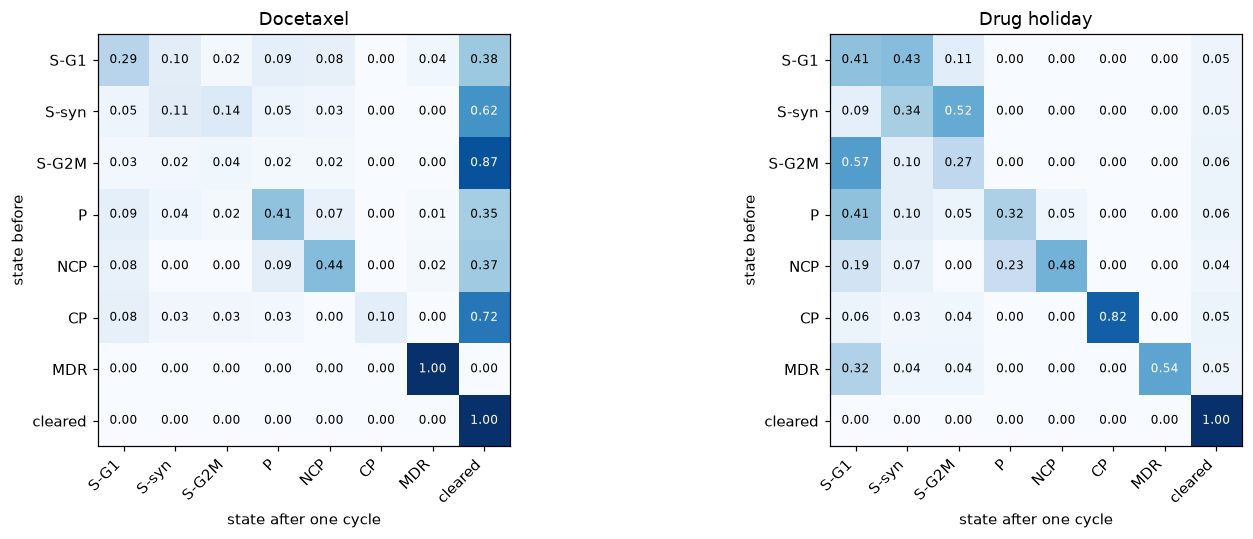

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
show_matrix(doc_matrix, "Docetaxel", ax=axes[0])
show_matrix(holiday_matrix, "Drug holiday", ax=axes[1])
plt.tight_layout()
plt.show()

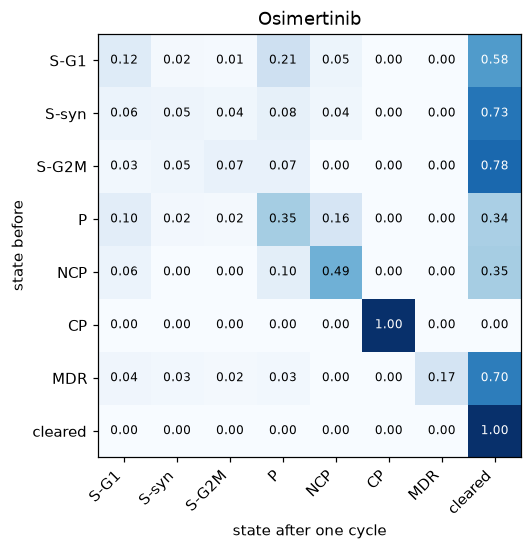

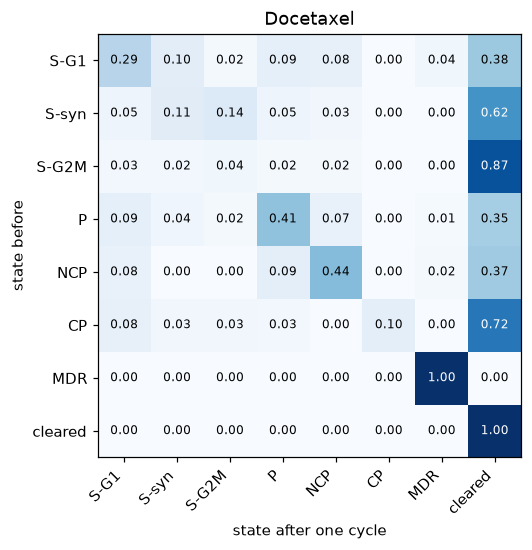

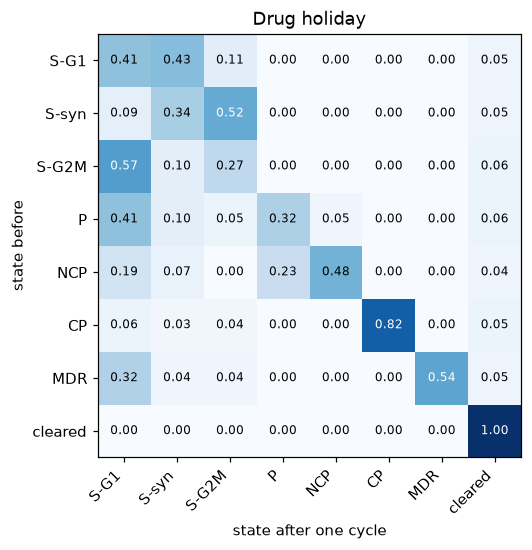

In [124]:
#Plot the transition matrices for docetaxel and the drug holiday.
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat, title="Osimertinib")
show_matrix(P_doc_df, title="Docetaxel")
show_matrix(P_holiday_df, title="Drug holiday")

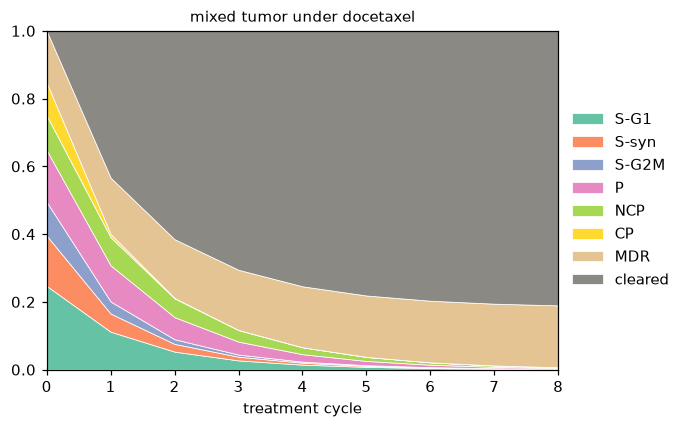

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


In [125]:
# Simulate the evolution of pi_mix under docetaxel 

pi_mix =   cells [cells[ "timepoint"] == "A"]["state"].value_counts(normalize = True).reindex(OUTCOMES, fill_value = 0).to_numpy()

traj_mix_doc = evolve(pi_mix, P_doc_df, N_CYCLES)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_mix_doc, ax, "mixed tumor under docetaxel")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()



pd.DataFrame(traj_mix_doc, columns=OUTCOMES).round(3)

ANSWER: 

1. Cleared is absorbing in all three conditions. Under osimertinib, CP is also absorbing and no other state enters it. Under docetaxel, MDR is absorbing and can receive cells from S-G1, P, and NCP. Docetaxel clears 72.4% of CP cells in one cycle. During a holiday, cleared is the only absorbing state. Living cells can again change state, including S-G1 → S-syn → S-G2M → S-G1. A cell may take other paths as well.

2. By cycle 8, 81.04% of original cells have cleared. MDR grows from 15.30% to about 18.3% of the original cells and accounts for roughly 96% of survivors. That increase reflects cells entering MDR as well as cells already there surviving. With osimertinib, by contrast, the original CP fraction stays constant while its share among survivors grows.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

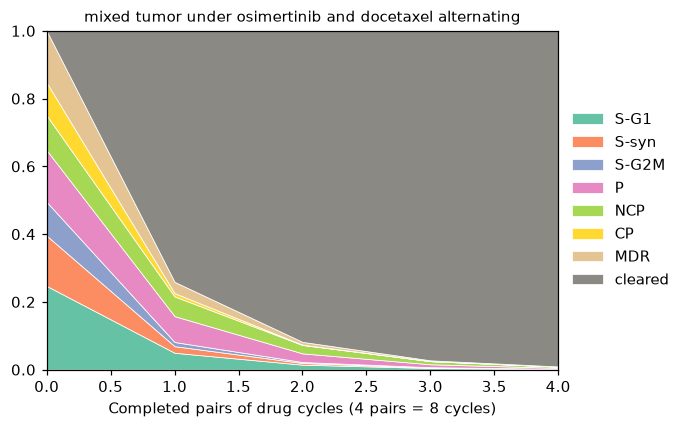

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.050,0.019,0.012,0.076,0.058,0.010,0.033,0.741
2,0.015,0.005,0.003,0.026,0.025,0.001,0.008,0.918
3,0.005,0.002,0.001,0.009,0.009,0.000,0.002,0.973
4,0.002,0.001,0.000,0.003,0.003,0.000,0.001,0.991


In [126]:
## Add code here

# Simulate the evolution of pi_mix under osimertinib and docetaxel alternating starting with osimertinib

pi_mix =   cells [cells[ "timepoint"] == "A"]["state"].value_counts(normalize = True).reindex(OUTCOMES, fill_value = 0).to_numpy()

traj_alt_OD = evolve(pi_mix, P_osi @ P_doc, 4)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_alt_OD, ax, "mixed tumor under osimertinib and docetaxel alternating")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_xlabel("Completed pairs of drug cycles (4 pairs = 8 cycles)")
plt.show()



pd.DataFrame(traj_alt_OD, columns=OUTCOMES).round(3)

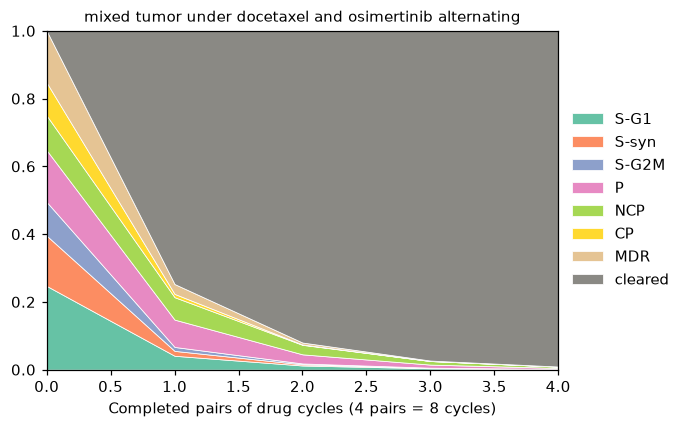

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.041,0.014,0.012,0.081,0.066,0.010,0.029,0.747
2,0.012,0.003,0.003,0.027,0.028,0.001,0.006,0.920
3,0.004,0.001,0.001,0.009,0.011,0.000,0.001,0.973
4,0.001,0.000,0.000,0.003,0.004,0.000,0.000,0.991


In [127]:
## Add code here

# Simulate the evolution of pi_mix under alternations of docetaxel and osimertinib starting with doce

pi_mix =   cells [cells[ "timepoint"] == "A"]["state"].value_counts(normalize = True).reindex(OUTCOMES, fill_value = 0).to_numpy()

traj_alt_OD = evolve(pi_mix, P_doc @ P_osi, 4)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_alt_OD, ax, "mixed tumor under docetaxel and osimertinib alternating")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_xlabel("Completed pairs of drug cycles (4 pairs = 8 cycles)")
plt.show()



pd.DataFrame(traj_alt_OD, columns=OUTCOMES).round(3)

1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.

ANSWER:

For the measured mix, docetaxel alone clears 81.04% and osimertinib alone clears 89.34%. Alternation clears 99.06% starting with osimertinib (O) and 99.08% starting with docetaxel (D). Each drug can clear a state that resists the other. Roughly 1% of the original cells still survive.

2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?

ANSWER:

For this mix, the difference is about 0.02 percentage points, and both orders first reach 99% at cycle 8. Order does affect the mix of survivors: for example, starting with D leaves about 0.4% of original cells in NCP versus about 0.3% starting with O. Rounded zeros do not establish that a state disappeared. For other starting tumors, order can change how early a target is reached.

3.  In what situation would a drug holiday help clear the tumor?

ANSWER:

During a holiday, about 32% of MDR, 41% of P, and 19% of NCP cells transition to S-G1 in one cycle. That gives the next drug a chance to clear cells that might otherwise persist. For an all-MDR start, one holiday followed by seven D cycles clears 43.17%, versus 0% under eight D cycles. For the measured mix, that holiday schedule clears 87.80%, below either alternating schedule at the same eight-cycle endpoint.

In [128]:
plans8 = {"O only": "O"*8, "D only": "D"*8, "OD": "OD"*4,
          "DO": "DO"*4, "Holiday then D": "H" + "D"*7}
matrices = {"O": P_osi, "D": P_doc, "H": P_holiday}
starting_vectors = {"Measured mix": pi_mix,
                    **{s: basis(s, P_hat) for s in ["CP", "MDR", "S-G2M"]}}
records = []
for name, start in starting_vectors.items():
    for label, sequence in plans8.items():
        pi = start.copy()
        first = None
        for cycle, drug in enumerate(sequence, 1):
            pi = pi @ matrices[drug]
            if first is None and pi[-1] >= 0.99:
                first = cycle
        records.append([name, label, 100*pi[-1], first])
summary8 = pd.DataFrame(records, columns=["Start", "Schedule", "% cleared", "First cycle at 99%"])
display(summary8.pivot(index="Schedule", columns="Start", values="% cleared").round(2))
display(summary8.pivot(index="Schedule", columns="Start", values="First cycle at 99%").astype("Int64"))

Start,CP,MDR,Measured mix,S-G2M
Schedule,,,,
D only,98.99,0.00,81.04,99.41
DO,99.64,99.27,99.08,99.79
Holiday then D,98.46,43.17,87.80,95.10
O only,0.00,99.71,89.34,99.64
OD,99.36,99.52,99.06,99.68


Start,CP,MDR,Measured mix,S-G2M
Schedule,,,,
D only,<NA>,<NA>,<NA>,6
DO,7,8,8,6
Holiday then D,<NA>,<NA>,<NA>,<NA>
O only,<NA>,6,<NA>,6
OD,8,7,8,6


In [129]:
equal_mix = np.array([1/7] * 7 + [0])
alt2 = np.linalg.matrix_power(P_osi @ P_doc, 2)    
pair_with_holidays = P_osi @ P_holiday @ P_doc @ P_holiday
pair_with_holidays_DO = P_doc @ P_holiday @ P_osi @ P_holiday

high_ncp = np.array([0.10, 0.10, 0.10, 0.10, 0.40, 0.10, 0.10, 0.0])
#                   S-G1  S-syn S-G2M  P    NCP   CP    MDR  cleared
assert np.isclose(high_ncp.sum(), 1)

high_p = np.array([0.10, 0.10, 0.10, 0.40, 0.10, 0.10, 0.10, 0.0])
#                   S-G1  S-syn S-G2M  P    NCP   CP    MDR  cleared

schedules = {
    "osi x8":      np.linalg.matrix_power(P_osi, 8),
    "doc x8":      np.linalg.matrix_power(P_doc, 8),
    "alt O->D x8": np.linalg.matrix_power(P_osi @ P_doc, 4),
    "alt D->O x8": np.linalg.matrix_power(P_doc @ P_osi, 4),
    "holiday, then alt O->D x8": P_holiday @ np.linalg.matrix_power(P_osi @ P_doc, 4),
    "alt O->D x8, then holiday": np.linalg.matrix_power(P_osi @ P_doc, 4) @ P_holiday,
    "O, D, holiday (x4)":        np.linalg.matrix_power(P_osi @ P_doc @ P_holiday, 4),
    "alt2 between hold": alt2 @ P_holiday @ alt2,
    "O,H,D,H... (no final H)": np.linalg.matrix_power(pair_with_holidays, 3) @ P_osi @ P_holiday @ P_doc,
    "D,H,O,H... (no final H)": np.linalg.matrix_power(pair_with_holidays_DO, 3) @ P_doc @ P_holiday @ P_osi,
    "O,H,D,H... (no final H) 2": np.linalg.matrix_power(pair_with_holidays, 2) @ P_osi @ P_holiday @ P_doc,
    "D,H,O,H... (no final H) 2": np.linalg.matrix_power(pair_with_holidays_DO, 2) @ P_doc @ P_holiday @ P_osi
}
starts = {
    "all CP":  basis("CP", P_hat),
    "all MDR": basis("MDR", P_hat),
    "all P":  basis("P", P_hat),
    "all NCP": basis("NCP", P_hat),
    "mix":     pi_mix,
    "equalmix": equal_mix,
    "high NCP": high_ncp,
    "high P": high_p,
    
}

table = pd.DataFrame({s_name: {sch_name: (start @ M)[-1]          # fraction cleared
                               for sch_name, M in schedules.items()}
                      for s_name, start in starts.items()})
table.round(3)

,all CP,all MDR,all P,all NCP,mix,equalmix,high NCP,high P
osi x8,0.000,0.997,0.981,0.978,0.893,0.848,0.887,0.888
doc x8,0.990,0.000,0.945,0.932,0.810,0.825,0.857,0.861
alt O->D x8,0.994,0.995,0.983,0.981,0.991,0.991,0.988,0.988
alt D->O x8,0.996,0.993,0.985,0.983,0.991,0.991,0.989,0.989
"holiday, then alt O->D x8",0.994,0.994,0.989,0.985,0.992,0.992,0.990,0.991
"alt O->D x8, then holiday",0.994,0.995,0.984,0.982,0.991,0.991,0.988,0.989
"O, D, holiday (x4)",0.997,0.997,0.993,0.992,0.996,0.996,0.995,0.995
alt2 between hold,0.995,0.996,0.987,0.986,0.993,0.993,0.991,0.991
"O,H,D,H... (no final H)",0.998,0.999,0.997,0.997,0.998,0.998,0.998,0.998
"D,H,O,H... (no final H)",0.999,0.998,0.998,0.997,0.998,0.998,0.998,0.998


4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

ANSWER:

In our discussion with Dr. Groves, the question about treating the whole person led to a choice we could examine in the lab: how many rounds does it take to reach a stated goal? We used 99% clearance of the original cells as a working target. The results below compare the schedules we tested. The model tracks cell states and does not measure patient side effects.

Starting tumor	Schedule in the model	Reason
Measured mix	Alternate O and D for 8 rounds	Both orders reach the target at round 8. Starting with D gives a slight edge in final clearance.
All CP	Alternate starting with D for 7 rounds	D can clear CP in the first round. Starting with O takes 8 rounds to reach the same target.
All MDR	O alone for 6 rounds	D leaves every MDR cell in MDR. O alone reaches the target earlier than either alternating order.
All S-G2M	Either drug alone for 6 rounds	Both single-drug schedules reach the target at round 6.
Equal mix or persister-heavy mix	Compare alternating schedules at 8 rounds	Both orders clear about 99.1% of the equal mix. When 40% of starting cells are P or NCP, alternating clears about 98.8–98.9%, just below the target.

The extra schedules above explore this question. For the measured mix, six alternating drug doses separated by five holidays clear about 99.1–99.2% over 11 elapsed cycles. Eight alternating drug doses separated by seven holidays clear about 99.8% over 15 elapsed cycles. These examples show how fewer doses or more time can change the result. The 11- and 15-cycle schedules answer a different question from the required eight-cycle comparison. The simulations alone cannot determine whether a longer course or a break is preferable for an actual patient.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [130]:
rng = np.random.default_rng(100)

In [131]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [132]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

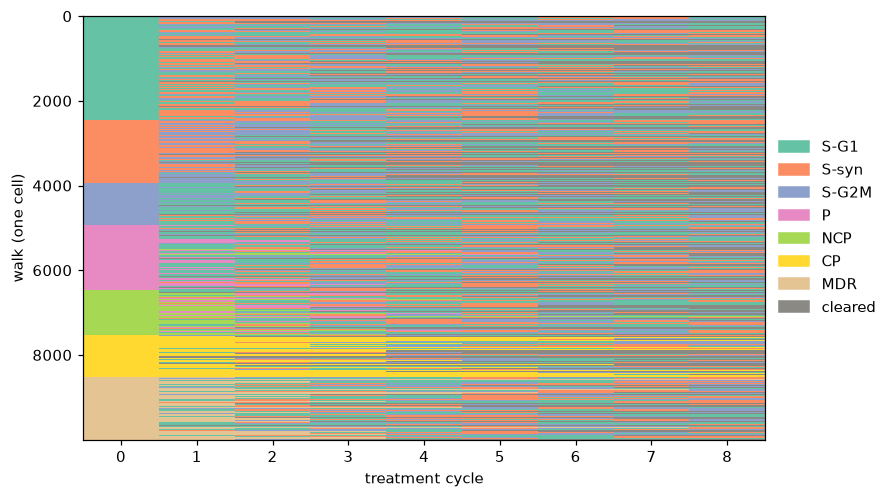

In [133]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [134]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

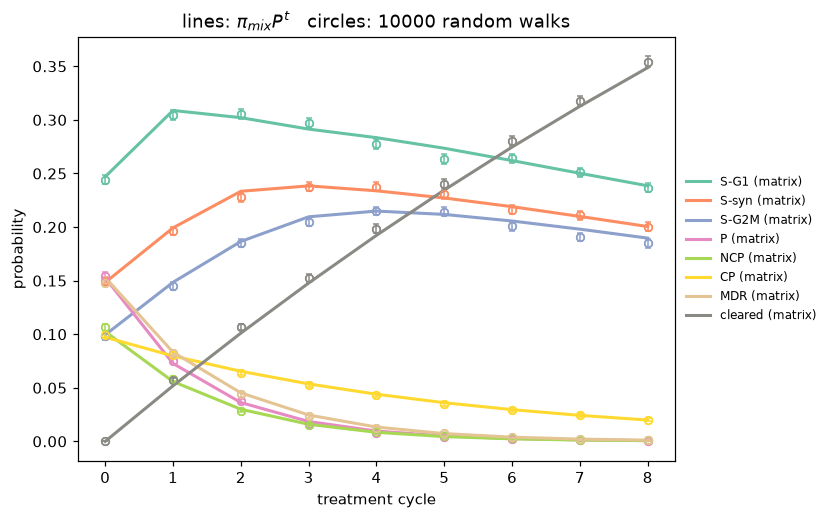

In [135]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?

ANSWER:

With 10,000 walks, the circles generally fall closer to the lines, and the error bars are smaller. The circles show the simulated fraction of cells in each state, while the lines show the probabilities predicted by the transition matrix. Using 100 times as many independent walks reduces the standard error by a factor of 10, so the simulated fractions fluctuate less around the predictions.

With 100 walks, the circles show visible gaps from the lines. With 10,000 walks, the circles generally fall much closer to the lines, and the error bars shrink. The lines give the state probabilities predicted by the transition matrix during the drug holiday. Each circle shows the fraction of simulated cells actually in that state at that cycle.

Each cell randomly draws its next state using the probabilities for its current state. With only 100 walks, a few cells taking a rare transition can visibly shift the fraction. With 10,000 walks, the observed fractions are more stable. Increasing the number of walks by a factor of 100 reduces the standard error by about a factor of 10.</div>

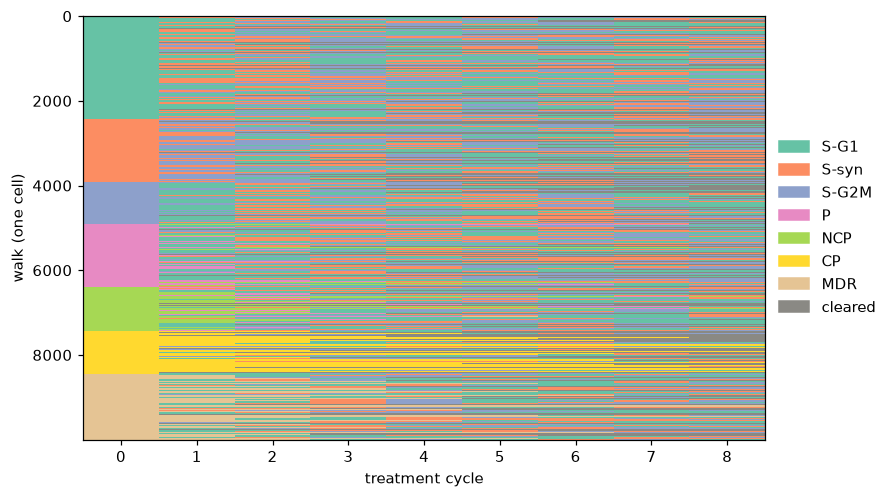

In [136]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

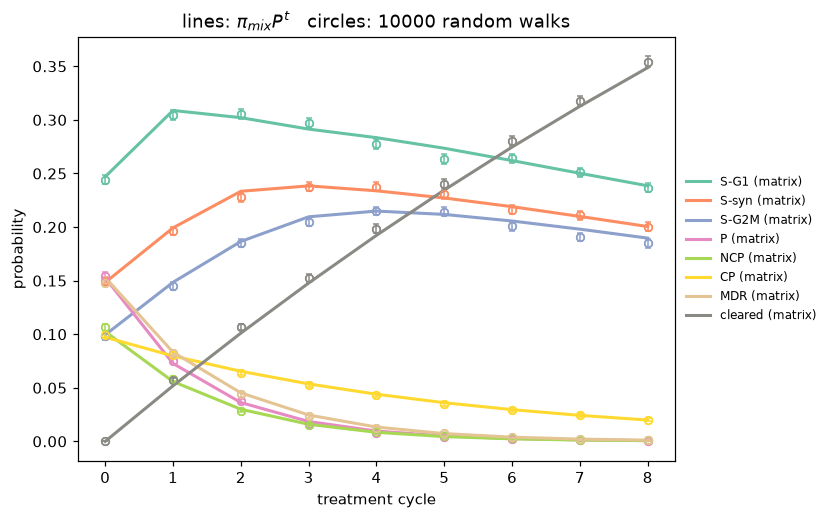

In [137]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

ANSWER:

With 100 walks, random variation is visible between the circles (sample proportions) and the lines (matrix probabilities). With 10,000 walks the circles generally lie closer to the lines and the error bars shrink. Increasing the sample size 100-fold reduces a proportion’s standard error by a factor of 10. The underlying probabilities stay the same.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [138]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

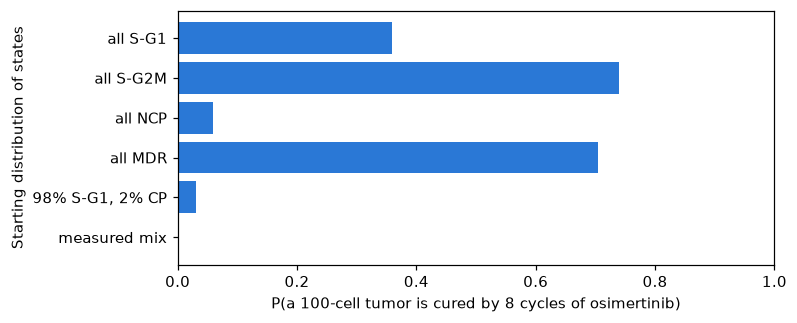

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.360,1.030,0.000
all S-G2M,0.740,0.290,0.000
all NCP,0.060,2.185,0.000
all MDR,0.705,0.325,0.000
"98% S-G1, 2% CP",0.030,3.175,0.639
measured mix,0.000,10.635,0.913


In [139]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

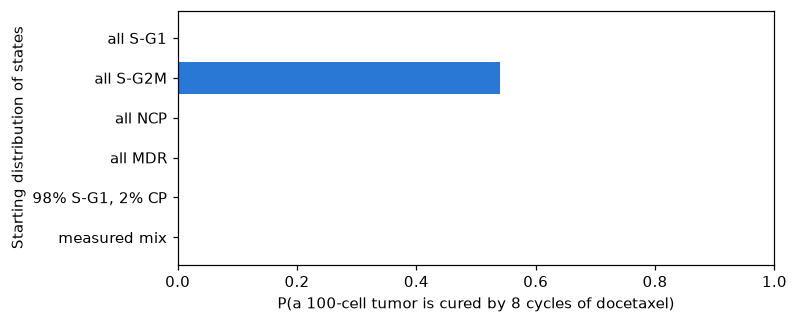

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.00,7.410,0.0
all S-G2M,0.54,0.555,0.0
all NCP,0.00,6.725,0.0
all MDR,0.00,100.000,0.0
"98% S-G1, 2% CP",0.00,7.220,0.0
measured mix,0.00,18.565,0.0


In [140]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

ANSWER:

A tumor counts as cured only when all 100 cells clear. Under docetaxel, 116 of 200 all-S-G2M tumors and 1 of 200 all-S-G1 tumors cleared. No complete clearances occurred in the other four scenarios. All 100 cells survived in every all-MDR tumor because MDR is absorbing under D.

Neither simulation run observed complete clearance of a measured-mix tumor under either drug. In the docetaxel run, an average of 18.735 cells survived and 95.7% of survivors were MDR. Under osimertinib the two runs averaged 10.405 and 10.685 survivors, of which 91.4% and 91.8% were CP, respectively. Differences between random runs are expected. Across both, the starting mix and the identity of the survivors help explain why high individual-cell clearance can coexist with a low chance of clearing an entire tumor.

We each simulated 200 tumors of 100 cells for each starting condition. A tumor counted as completely cleared only if all 100 cells cleared by the end of eight docetaxel cycles.

| Starting condition | My run: tumors completely cleared | My partner’s run: tumors completely cleared |
|---|---:|---:|
| All S-G1 | 1/200 (0.5%) | 0/200 (0%) |
| All S-G2M | 116/200 (58%) | 109/200 (54.5%) |
| All NCP | 0/200 (0%) | 0/200 (0%) |
| All MDR | 0/200 (0%) | 0/200 (0%) |
| 98% S-G1, 2% CP | 0/200 (0%) | 1/200 (0.5%) |
| Measured mix | 0/200 (0%) | 0/200 (0%) |

In both runs, all-S-G2M tumors cleared most often. The exact counts differed because each simulation sampled random cell paths. The largest contrast between drugs was in the all-MDR tumors. Osimertinib completely cleared 75% of those tumors in my run. Under docetaxel, every MDR cell survived in both runs because MDR is an absorbing state for that drug.

My partner pointed out that clearing a high percentage of cells can still leave a tumor with surviving cells. For the measured mix, the matrix predicted that docetaxel would clear about 81% of cells. Yet neither of us observed a single completely cleared tumor: my run averaged 18.735 surviving cells per tumor, and hers averaged 18.955. Most of those survivors were MDR cells (95.7% in my run and 96.4% in hers).

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [141]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test

pr_rng = np.random.default_rng(5030)
persister_states = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

def simulate_pr_tumor(schedule, rng, n_cells=1000):
    # Each row is one cell. Column 0 is its state before treatment.
    paths = np.empty((n_cells, len(schedule) + 1), dtype=int)
    paths[:, 0] = rng.choice(len(OUTCOMES), size=n_cells, p=pi_mix)

    streak = np.zeros(n_cells, dtype=int)  # Baseline precedes the first treatment.
    pr_state = len(OUTCOMES)  # New absorbing state for permanent resistance

    for cycle, matrix in enumerate(schedule, start=1):
        previous = paths[:, cycle - 1]
        current = previous.copy()  # Cells already in PR stay there.

        for state, probabilities in enumerate(matrix):
            group = previous == state
            current[group] = rng.choice(
                len(OUTCOMES), size=group.sum(), p=probabilities
            )

        in_persister = np.isin(current, persister_states)
        streak = np.where(in_persister, streak + 1, 0)
        current[streak >= 3] = pr_state
        paths[:, cycle] = current

    return paths

pr_schedules = {
    "Osimertinib alone": [P_osi] * 8,
    "Docetaxel alone": [P_doc] * 8,
    "Alternating O then D": [P_osi, P_doc] * 4,
    "One holiday, then 7 D": [P_holiday] + [P_doc] * 7,
}

pr_state = len(OUTCOMES)
percent_above = {}
for name, schedule in pr_schedules.items():
    # One row per tumor, one column per completed cycle.
    pr_counts = np.array([
        (simulate_pr_tumor(schedule, pr_rng)[:, 1:] == pr_state).sum(axis=0)
        for _ in range(100)
    ])

    # More than 10% of 1,000 cells means at least 101 PR cells.
    percent_above[name] = 100 * (pr_counts > 100).mean(axis=0)

    if name == "Osimertinib alone":
        final_percent = 100 * pr_counts[:, -1] / 1000
        mean_pr = final_percent.mean()
        sem_pr = final_percent.std(ddof=1) / np.sqrt(len(final_percent))

# 95% t interval for the mean across 100 independent tumors (99 df).
low = mean_pr - 1.984 * sem_pr
high = mean_pr + 1.984 * sem_pr
print(f"Osimertinib after 8 cycles: mean PR = {mean_pr:.2f}%")
print(f"SEM = {sem_pr:.2f} percentage points; 95% CI = [{low:.2f}%, {high:.2f}%]")

print("Percentage of tumors with more than 10% permanently resistant cells")
pr_table = pd.DataFrame(percent_above, index=range(1, 9))
display(pr_table.rename_axis("Completed cycles"))

Osimertinib after 8 cycles: mean PR = 8.41%
SEM = 0.08 percentage points; 95% CI = [8.26%, 8.57%]
Percentage of tumors with more than 10% permanently resistant cells


,Osimertinib alone,Docetaxel alone,Alternating O then D,"One holiday, then 7 D"
Completed cycles,,,,
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0


In [142]:
pr_rng = np.random.default_rng(5030)
persister_states = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

def simulate_pr_tumor(schedule, rng, n_cells=1000):
    # Each row is one cell. Column 0 is its state before treatment.
    paths = np.empty((n_cells, len(schedule) + 1), dtype=int)
    paths[:, 0] = rng.choice(len(OUTCOMES), size=n_cells, p=pi_mix)

    streak = np.zeros(n_cells, dtype=int)
    pr_state = len(OUTCOMES)  # New absorbing state for permanent resistance

    for cycle, matrix in enumerate(schedule, start=1):
        previous = paths[:, cycle - 1]
        current = previous.copy()  # Cells already in PR stay there.

        for state, probabilities in enumerate(matrix):
            group = previous == state
            current[group] = rng.choice(
                len(OUTCOMES), size=group.sum(), p=probabilities
            )

        in_persister = np.isin(current, persister_states)
        streak = np.where(in_persister, streak + 1, 0)
        current[streak >= 3] = pr_state
        paths[:, cycle] = current

    return paths

pr_schedules = {
    "Osimertinib alone": [P_osi] * 8,
    "Docetaxel alone": [P_doc] * 8,
    "Alternating O then D": [P_osi, P_doc] * 4,
    "One holiday, then 7 D": [P_holiday] + [P_doc] * 7,
}

pr_state = len(OUTCOMES)
percent_above = {}
for name, schedule in pr_schedules.items():
    # One row per tumor, one column per completed cycle.
    pr_counts = np.array([
        (simulate_pr_tumor(schedule, pr_rng)[:, 1:] == pr_state).sum(axis=0)
        for _ in range(100)
    ])

    # More than 10% of 1,000 cells means at least 101 PR cells.
    percent_above[name] = 100 * (pr_counts > 100).mean(axis=0)

    if name == "Osimertinib alone":
        final_percent = 100 * pr_counts[:, -1] / 1000
        mean_pr = final_percent.mean()
        sem_pr = final_percent.std(ddof=1) / np.sqrt(len(final_percent))

# 95% t interval for the mean across 100 independent tumors (99 df).
low = mean_pr - 1.984 * sem_pr
high = mean_pr + 1.984 * sem_pr
print(f"Osimertinib after 8 cycles: mean PR = {mean_pr:.2f}%")
print(f"SEM = {sem_pr:.2f} percentage points; 95% CI = [{low:.2f}%, {high:.2f}%]")

print("Percentage of tumors with more than 10% permanently resistant cells")
pr_table = pd.DataFrame(percent_above, index=range(1, 9))
display(pr_table.rename_axis("Completed cycles"))

Osimertinib after 8 cycles: mean PR = 8.41%
SEM = 0.08 percentage points; 95% CI = [8.26%, 8.57%]
Percentage of tumors with more than 10% permanently resistant cells


,Osimertinib alone,Docetaxel alone,Alternating O then D,"One holiday, then 7 D"
Completed cycles,,,,
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0


ANSWER:

Repeat with the pretreatment state counted as the first observation. A cell starting in P or NCP can now qualify after two completed cycles. Each run uses the same starting distribution, schedules and seed.

In [143]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test

pr_rng = np.random.default_rng(5030)
persister_states = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

def simulate_pr_tumor(schedule, rng, n_cells=1000):
    # Each row is one cell. Column 0 is its state before treatment.
    paths = np.empty((n_cells, len(schedule) + 1), dtype=int)
    paths[:, 0] = rng.choice(len(OUTCOMES), size=n_cells, p=pi_mix)

    streak = np.isin(paths[:, 0], persister_states).astype(int)
    pr_state = len(OUTCOMES)  # New absorbing state for permanent resistance

    for cycle, matrix in enumerate(schedule, start=1):
        previous = paths[:, cycle - 1]
        current = previous.copy()  # Cells already in PR stay there.

        for state, probabilities in enumerate(matrix):
            group = previous == state
            current[group] = rng.choice(
                len(OUTCOMES), size=group.sum(), p=probabilities
            )

        in_persister = np.isin(current, persister_states)
        streak = np.where(in_persister, streak + 1, 0)
        current[streak >= 3] = pr_state
        paths[:, cycle] = current

    return paths

pr_schedules = {
    "Osimertinib alone": [P_osi] * 8,
    "Docetaxel alone": [P_doc] * 8,
    "Alternating O then D": [P_osi, P_doc] * 4,
    "One holiday, then 7 D": [P_holiday] + [P_doc] * 7,
}

pr_state = len(OUTCOMES)
percent_above = {}
for name, schedule in pr_schedules.items():
    # One row per tumor, one column per completed cycle.
    pr_counts = np.array([
        (simulate_pr_tumor(schedule, pr_rng)[:, 1:] == pr_state).sum(axis=0)
        for _ in range(100)
    ])

    # More than 10% of 1,000 cells means at least 101 PR cells.
    percent_above[name] = 100 * (pr_counts > 100).mean(axis=0)

    if name == "Osimertinib alone":
        final_percent = 100 * pr_counts[:, -1] / 1000
        mean_pr = final_percent.mean()
        sem_pr = final_percent.std(ddof=1) / np.sqrt(len(final_percent))

# 95% t interval for the mean across 100 independent tumors (99 df).
low = mean_pr - 1.984 * sem_pr
high = mean_pr + 1.984 * sem_pr
print(f"Osimertinib after 8 cycles: mean PR = {mean_pr:.2f}%")
print(f"SEM = {sem_pr:.2f} percentage points; 95% CI = [{low:.2f}%, {high:.2f}%]")

print("Percentage of tumors with more than 10% permanently resistant cells")
pr_table = pd.DataFrame(percent_above, index=range(1, 9))
display(pr_table.rename_axis("Completed cycles"))

Osimertinib after 8 cycles: mean PR = 11.62%
SEM = 0.10 percentage points; 95% CI = [11.41%, 11.83%]
Percentage of tumors with more than 10% permanently resistant cells


,Osimertinib alone,Docetaxel alone,Alternating O then D,"One holiday, then 7 D"
Completed cycles,,,,
1,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0
3,66.0,0.0,22.0,0.0
4,90.0,2.0,41.0,4.0
5,92.0,9.0,61.0,12.0
6,93.0,10.0,65.0,20.0
7,93.0,10.0,69.0,25.0
8,93.0,12.0,71.0,27.0


Osimertinib alone
Doxetaxel alone
Alternating OD
Doxetaxel with drug holiday

Percentage of 100 simulated tumors exceeding 10% PR cells after eight cycles
How the three-state streak is counted	O alone	D alone	Alternating OD	One holiday, then 7 D
Three completed cycles (primary)	0%	0%	0%	0%
Baseline counts as the first observation (sensitivity)	93%	12%	71%	27%

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday

ANSWER:

We simulated 100 tumors of 1,000 cells per schedule. A tumor crossed the 10% threshold once at least 101 of its original cells became permanently resistant (PR). We compared two ways of counting the three consecutive observations in P or NCP.

| How we counted the streak | Osimertinib alone | Docetaxel alone | Alternating O then D | One holiday, then seven D |
|---|---:|---:|---:|---:|
| Three completed cycles | 0% | 0% | 0% | 0% |
| Starting state counts as the first observation | 93% | 12% | 71% | 27% |

I counted three completed cycles because the prompt asks how long cells spend in a persister state during treatment. Under this rule, 0 of 100 tumors crossed the threshold under any schedule through cycle 8. Resistance still developed. After eight cycles of osimertinib, an average of 8.41% of cells per tumor were PR (SEM 0.08 percentage points, 95% CI 8.26–8.57%).

My partner counted the starting state because a cell already observed in P or NCP before treatment is already a persister. Under their rule, the percentage of tumors above the threshold changed as follows:

- **Osimertinib alone:** 1% crossed by cycle 2, 66% by cycle 3, and 93% by cycle 6. It stayed at 93% through cycle 8.
- **Docetaxel alone:** The percentage rose from 0% at cycle 3 to 2% at cycle 4 and 12% at cycle 8.
- **Alternating osimertinib and docetaxel:** The percentage rose from 22% at cycle 3 to 41% at cycle 4, 61% at cycle 5, and 71% at cycle 8.
- **One drug holiday followed by seven docetaxel cycles:** The percentage rose from 0% at cycle 3 to 4% at cycle 4 and 27% at cycle 8. Our model counts a cycle spent in P or NCP during a drug holiday toward the three-cycle resistance threshold, even though no drug is given that cycle.

Counting the starting state raised the mean PR fraction under osimertinib to 11.62% (SEM 0.10 percentage points, 95% CI 11.41–11.83%). That 11.62% describes the average share of cells that became resistant within a tumor. The 93% in the table answers a different question: 93 of the 100 simulated tumors had more than 10% resistant cells. </div>